# Receptive-field orientation, per area → `rf_orientation_FEF.pdf`, `rf_orientation_DMFC.pdf`

[`../figure_3/model_comparison/rf_orientation.ipynb`](../figure_3/model_comparison/rf_orientation.ipynb)'s
figure, drawn once over FEF neurons and once over DMFC neurons: where a neuron's fitted
2-object phase sits relative to its own 1-object receptive field, over every bootstrap. Rows are
the two models, columns the two monkeys.

The shared 2-object modulation criterion is applied first, over the whole population, exactly as
in the main text — the Benjamini–Hochberg correction for *that* criterion runs over every neuron
tested, so who is included must not depend on how they are later split. The **phase-determinacy**
cut then runs *within* an area and is BH-corrected across that area's neurons, so each figure's
contributing counts are genuinely its own rather than a subset of the pooled figure's.

The main-text notebook draws tuning insets above each panel and a separate key; they are a
legend for the x axis rather than a result, so they are omitted here and the reader is referred
to the main figure for them.

*Ported to the ordinal estimator on 2026-09-11.* The per-row cut is no longer a raw p on a
parametric fit but a Wald test on γ against its bootstrap covariance, BH-corrected at
`PHASE_FDR_Q` — so `config.P_THRESH_2OBJ` / `P_THRESH_1OBJ` are no longer read here. The
uniformity statistics the main text reports are printed below, per area.


In [1]:
import matplotlib.pyplot as plt

import common
common.set_style()
import stats_lib as sl

FIGSIZE = (5.7, 4.1)
OUTPUT = 'rf_orientation_{area}.pdf'

# ── These must match ../figure_3/model_comparison/rf_orientation.ipynb ─────────
N_BINS = 40
NULL_LINE = False         # the horizontal rule at 1/N_BINS — the density a uniform
                          #   distribution would have. Off, as in the main-text notebook;
                          #   `plot_phase_histograms` defaults it on for historical reasons.
PHASE_FDR_Q = sl.PHASE_FDR_Q        # determinacy: BH across the neurons of each area

# The uniformity tests draw their null rather than assuming an asymptotic form, so MC_DRAWS
# sets both the runtime and the floor on a reportable p: 1 / (MC_DRAWS + 1).
MC_DRAWS = 10000
MC_SEED = 0

# The population criterion, on as in the main text.
APPLY_MODULATION_CRITERION = True

# ── The tuning insets, matched to ../figure_3/model_comparison/rf_orientation.ipynb ──
# Drawn by `stats_lib.add_shift_insets`, the same function that notebook calls, so the
# supplement's insets cannot drift from the main text's.
INSET_SHIFTS_DEG = (-90, 0, 90, 180)   # where the insets sit on the x axis
INSET_RF_DEG = 90.0       # the 1-object receptive field every inset is measured against
INSET_SEP_DEG = 90.0      # inter-object angle of the chords inside each inset
INSET_N_ORIENT = 4        # chords per ring — four at 90 deg apart make the square v1 draws
INSET_SIZE_IN = 0.55      # side of an inset, in INCHES (they are square)
INSET_Y = 1.02            # bottom edge, in panel heights above the axis
INSET_TITLE_PAD = 6       # height of the column titles, in points above the axes
INSET_RADIUS = 0.38       # chord endpoints, in axes fractions from the inset's centre
INSET_ANNULUS_R = 0.44    # the 1-object annulus ...
INSET_ANNULUS_W = 0.06    # ... and its band width
INSET_LINEWIDTH = 2.0
ROW_HSPACE = 0.3          # vertical whitespace between the two model rows, as a fraction of
                          # axes height; opened before anything is placed, so the lower row's
                          # insets do not land inside the upper row's histogram
INSET_CONNECTOR_COLOR = '0.75'   # the line tying an inset to its x value: a pointer, not a
INSET_CONNECTOR_LW = 0.9         # datum, so it must never compete with the bars


In [2]:
units = sl.select_units(sl.load_units(), apply_modulation=APPLY_MODULATION_CRITERION)
phases = sl.load_phases()
per_area = common.by_area(units)

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
FEF: 660 neurons (Monkey P 405, Monkey E 255)
DMFC: 679 neurons (Monkey P 593, Monkey E 86)


Phase relative to the 1-object receptive field (all bootstraps):
  Monkey P —   Retinotopic: 238/405 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey P —   Relational: 243/405 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Retinotopic: 102/255 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Relational: 99/255 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)


saved rf_orientation_FEF.pdf


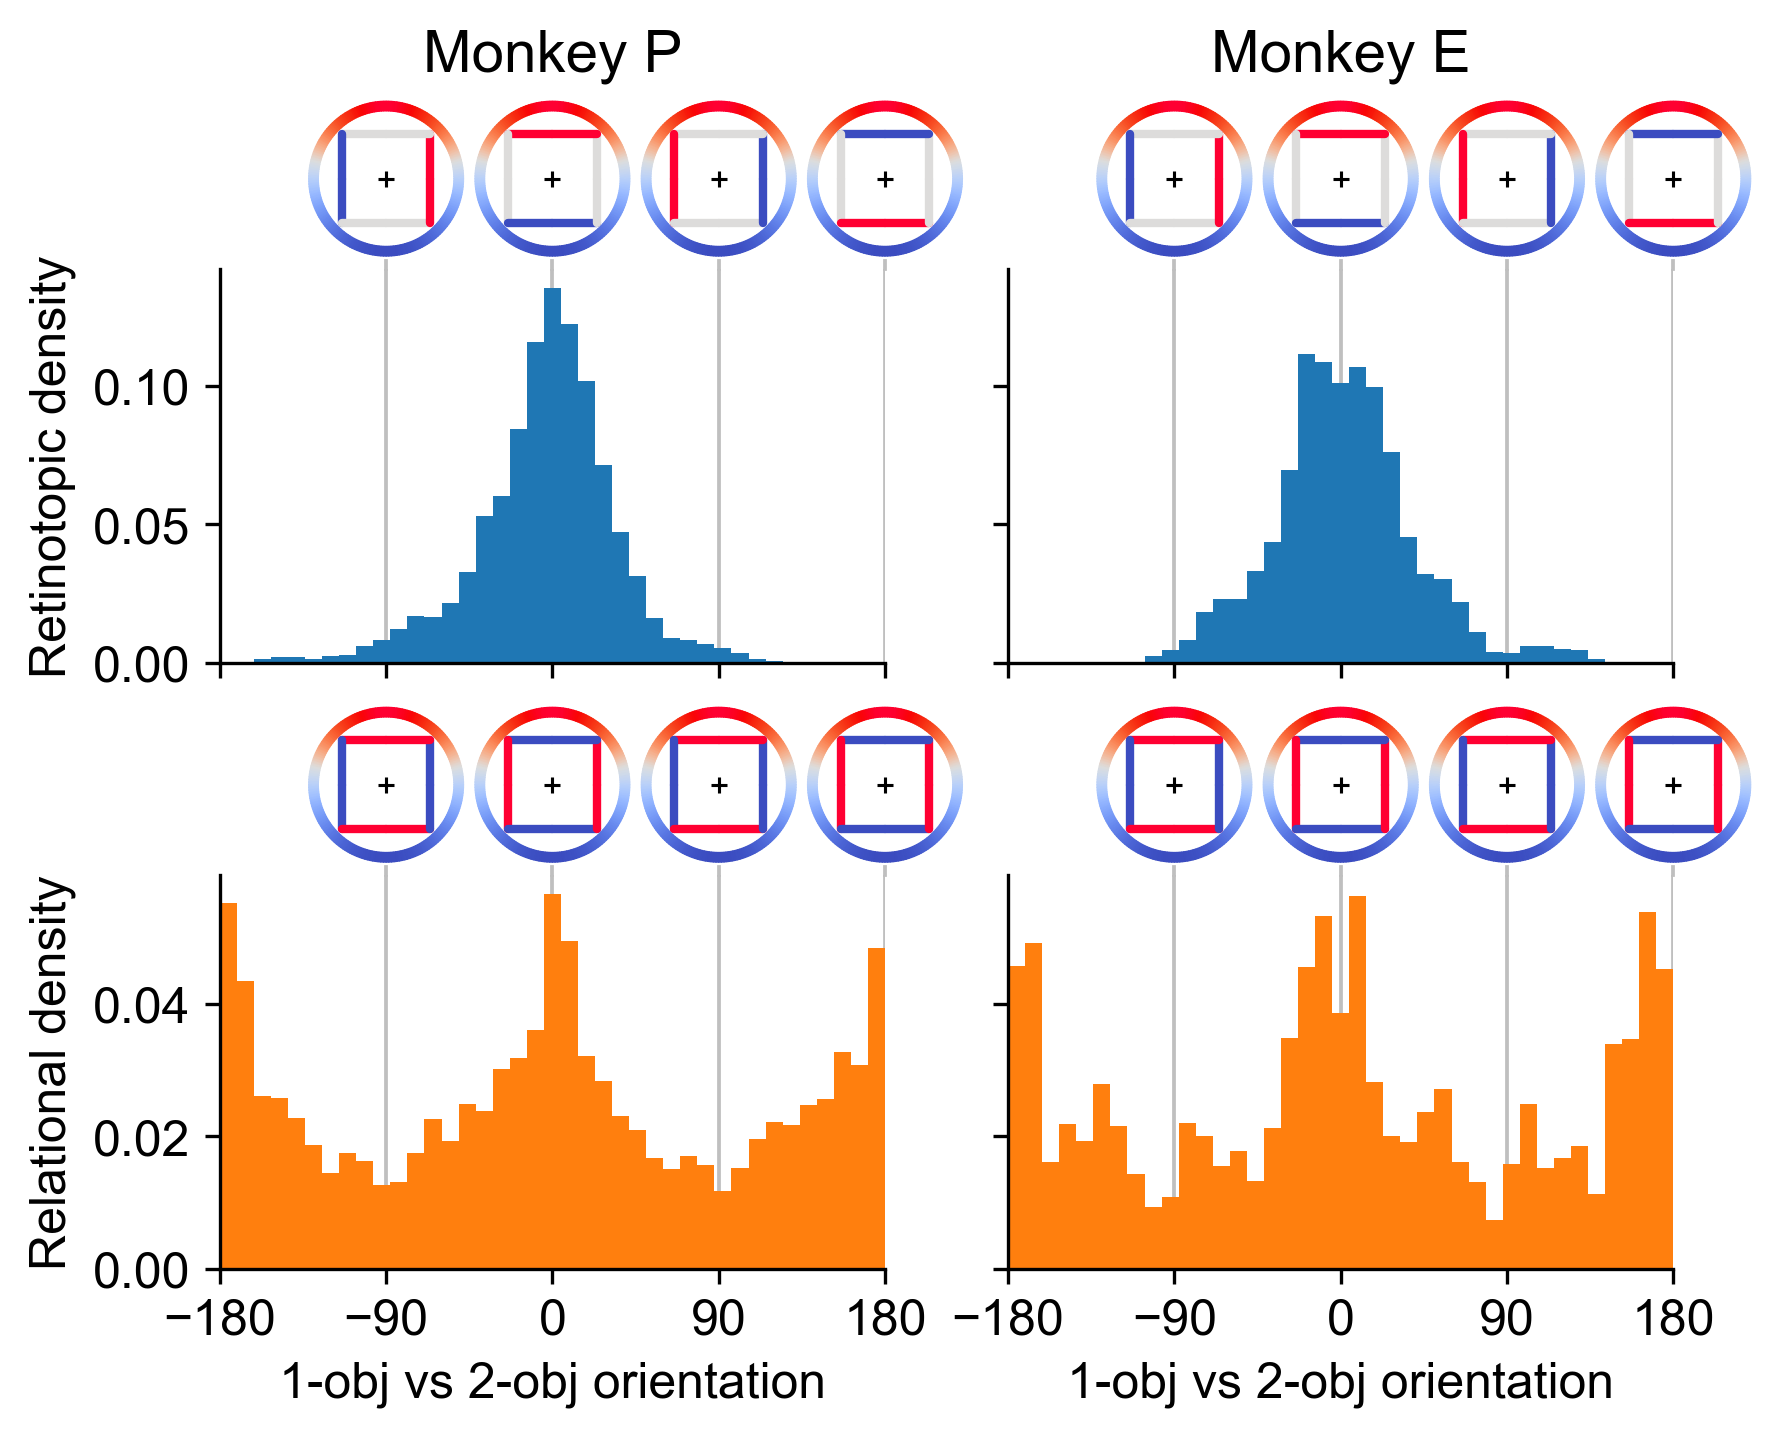

Phase relative to the 1-object receptive field (all bootstraps):
  Monkey P —   Retinotopic: 385/593 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey P —   Relational: 403/593 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Retinotopic: 48/86 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)
  Monkey E —   Relational: 49/86 neurons have a measurable phase (BH q=0.05, >= 100 1-obj trials)


saved rf_orientation_DMFC.pdf


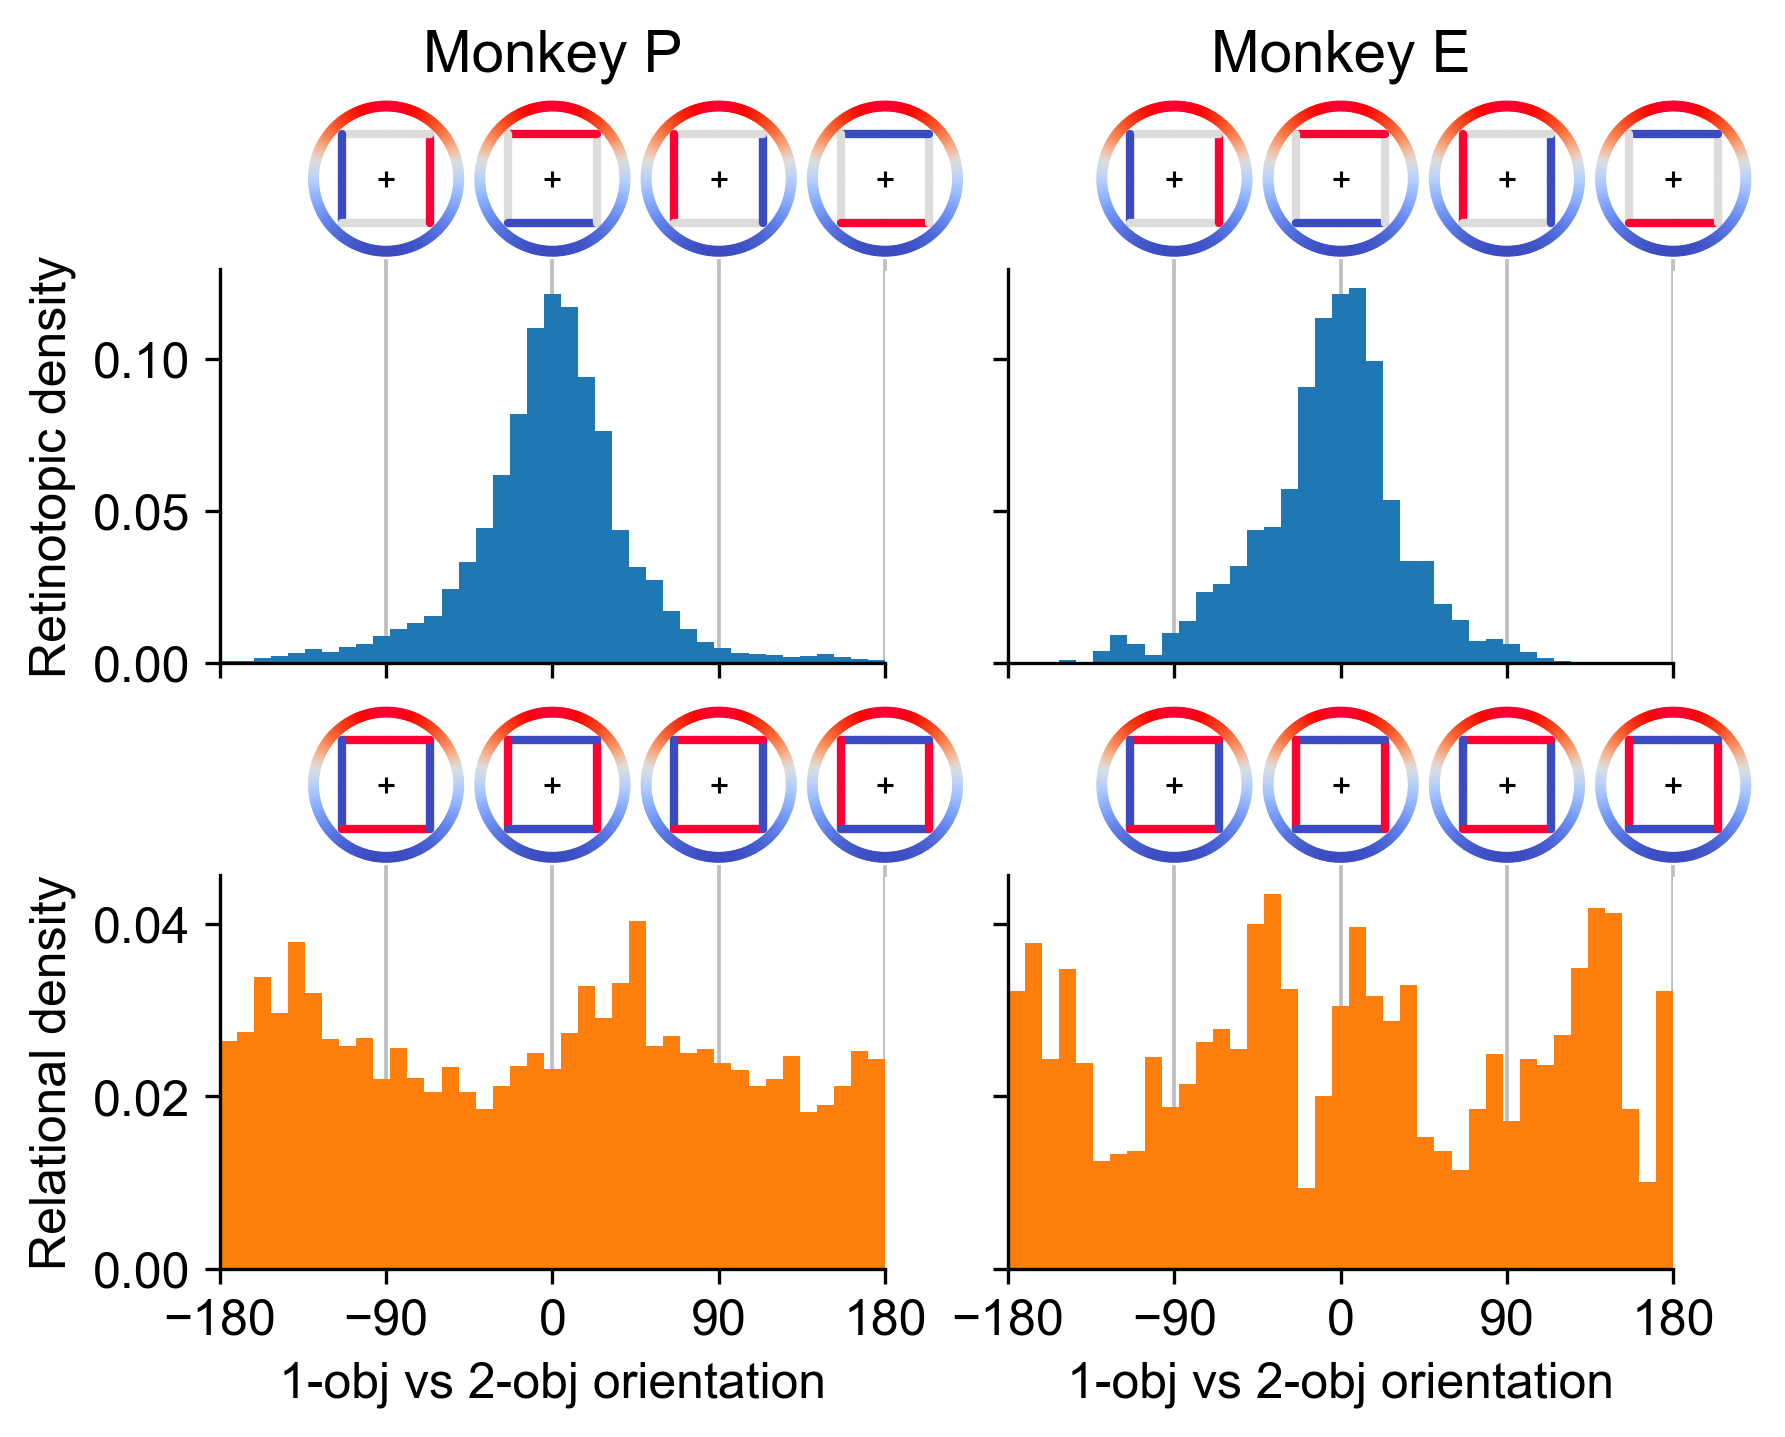

In [3]:
for area, area_units in per_area:
    fig, axes = sl.plot_phase_histograms(
        area_units, phases, n_bins=N_BINS, figsize=FIGSIZE, share_y='row', q=PHASE_FDR_Q,
        null_line=NULL_LINE)
    sl.add_shift_insets(fig, axes, sl.PHASE_MODELS, shifts_deg=INSET_SHIFTS_DEG,
                        rf_deg=INSET_RF_DEG, size_in=INSET_SIZE_IN, y=INSET_Y,
                        title_pad=INSET_TITLE_PAD, sep_deg=INSET_SEP_DEG,
                        n_orientations=INSET_N_ORIENT, radius=INSET_RADIUS,
                        annulus_radius=INSET_ANNULUS_R, annulus_width=INSET_ANNULUS_W,
                        linewidth=INSET_LINEWIDTH, hspace=ROW_HSPACE,
                        connector_color=INSET_CONNECTOR_COLOR,
                        connector_lw=INSET_CONNECTOR_LW)
    common.save(fig, OUTPUT.format(area=area))
    plt.show()

## What the criterion costs, and whether any of it is distinguishable from uniform

Both tables are the main-text notebook's, computed per area. The uniformity tests are given
**one value per neuron** from the point estimates — not the bootstrap draws the histogram plots,
which are resamples of the same neuron — and each row is tested on its own circle: 360° for the
retinotopic shift, which is a direction, 180° for the relational one, which is an axis. Testing
the relational row as a direction returns `R = 0.0000` for any data whatsoever, because the
plotted values come in pairs 180° apart.

In [4]:
import pandas as pd

for area, area_units in per_area:
    print(f'\n=== {area} ===')
    display(sl.exclusion_report(area_units, q=PHASE_FDR_Q))
    display(sl.uniformity_report(area_units, q=PHASE_FDR_Q, n_mc=MC_DRAWS, seed=MC_SEED))


=== FEF ===


,model,n,determinate_2obj,determinate_1obj,enough_1obj_trials,all_criteria
0,Retinotopic,660,532,416,596,353
1,Relational,660,577,416,596,354


,subject,model,period_deg,n_neurons,mean_shift_deg,resultant,rayleigh_p,kuiper_p
0,Monkey P,Retinotopic,360.0,238,357.9,0.837,0.0001,0.0001
1,Monkey P,Relational,180.0,243,177.9,0.273,0.0001,0.0001
2,Monkey E,Retinotopic,360.0,102,0.5,0.825,0.0001,0.0001
3,Monkey E,Relational,180.0,99,177.5,0.293,0.0003,0.0007



=== DMFC ===


,model,n,determinate_2obj,determinate_1obj,enough_1obj_trials,all_criteria
0,Retinotopic,679,548,504,648,434
1,Relational,679,629,504,648,452


,subject,model,period_deg,n_neurons,mean_shift_deg,resultant,rayleigh_p,kuiper_p
0,Monkey P,Retinotopic,360.0,385,359.7,0.789,0.000100,0.000100
1,Monkey P,Relational,180.0,403,39.6,0.115,0.003900,0.035396
2,Monkey E,Retinotopic,360.0,48,355.1,0.813,0.000100,0.000100
3,Monkey E,Relational,180.0,49,157.1,0.133,0.422658,0.578642
